       DENOISING AUTOENCODER - MNIST
TensorFlow: 2.20.0

Training images: (10000, 28, 28, 1)
Testing images : (1000, 28, 28, 1)


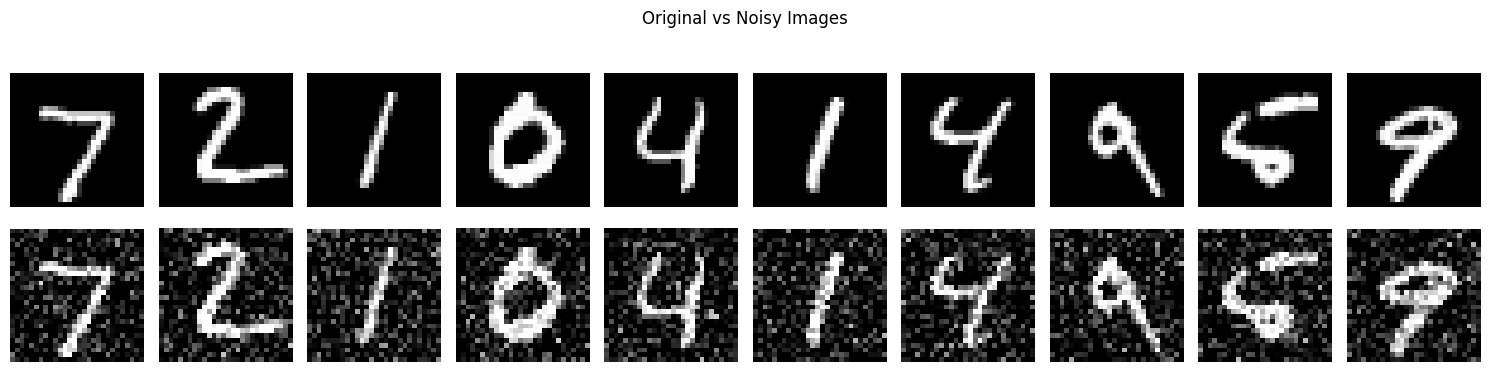


MODEL ARCHITECTURE


Model: "Denoising_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 14, 14, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 7, 7, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 7, 7, 16)       │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_3 (UpSampling2D)  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,193 (47.63 KB)

 Trainable params: 12,193 (47.63 KB)

 Non-trainable params: 0 (0.00 B)


TRAINING
Epoch 1/5
71/71 ━━━━━━━━━━━━━━━━━━━━ 20s 254ms/step - loss: 0.3741 - val_loss: 0.1923
Epoch 2/5
71/71 ━━━━━━━━━━━━━━━━━━━━ 19s 231ms/step - loss: 0.1518 - val_loss: 0.1330
Epoch 3/5
71/71 ━━━━━━━━━━━━━━━━━━━━ 17s 233ms/step - loss: 0.1203 - val_loss: 0.1146
Epoch 4/5
71/71 ━━━━━━━━━━━━━━━━━━━━ 17s 241ms/step - loss: 0.1072 - val_loss: 0.1055
Epoch 5/5
71/71 ━━━━━━━━━━━━━━━━━━━━ 20s 233ms/step - loss: 0.1007 - val_loss: 0.1007


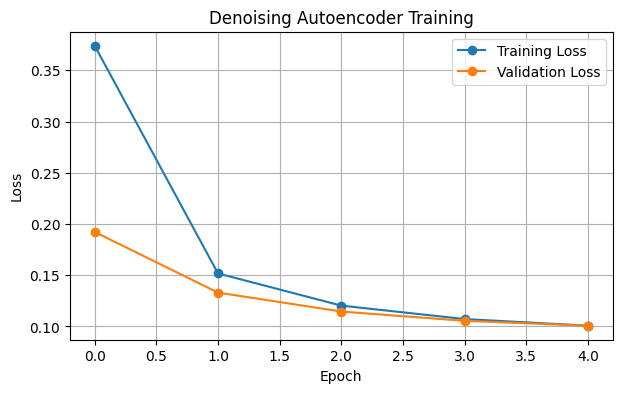


Denoised shape: (1000, 28, 28, 1)


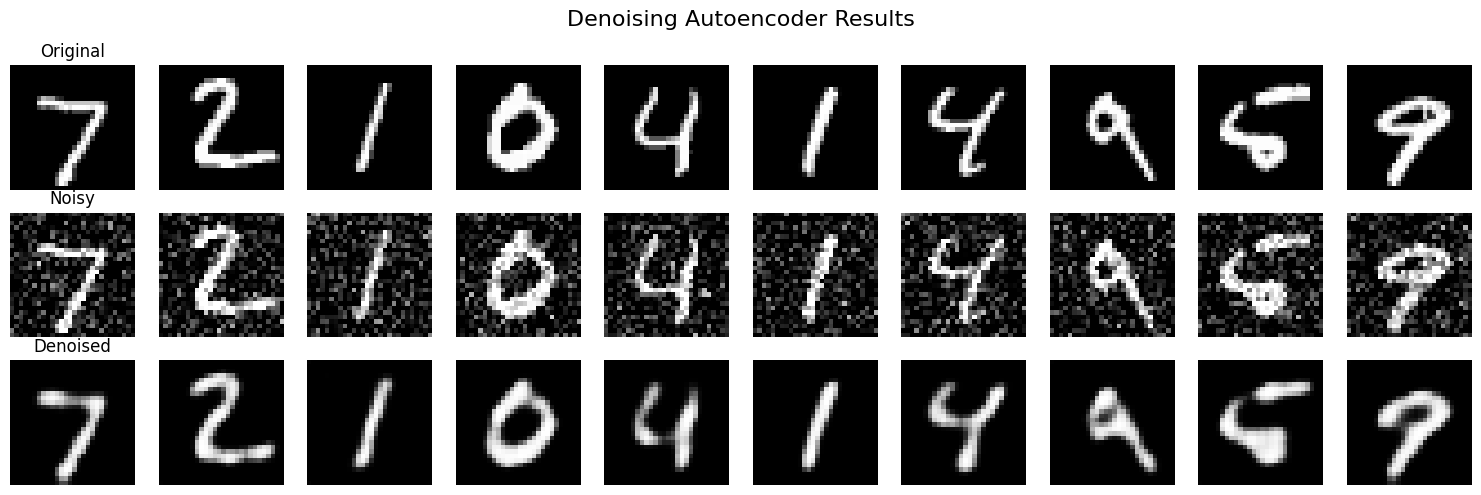


PERFORMANCE METRICS
Noisy MSE    : 0.032675
Denoised MSE : 0.011913
Noisy PSNR    : 14.87 dB
Denoised PSNR : 19.72 dB
Noisy SSIM    : 0.5551
Denoised SSIM : 0.8662

IMPROVEMENT AFTER DENOISING
MSE Reduction      : 63.54%
PSNR Improvement   : 4.85 dB
SSIM Improvement   : 0.3111


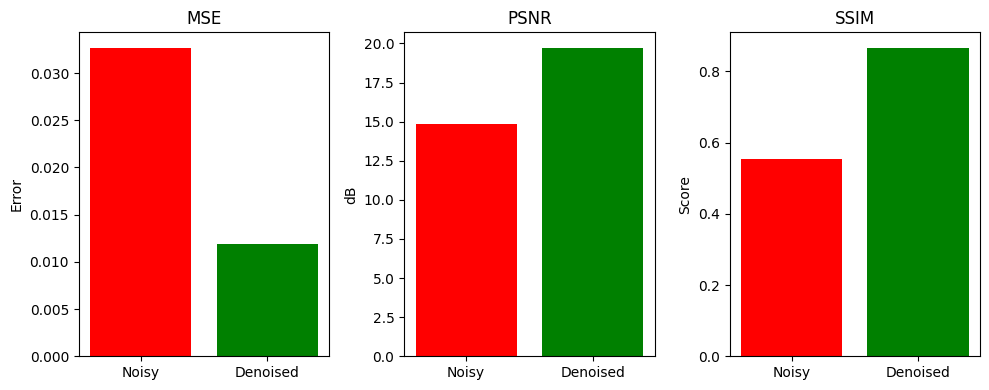


Model saved as:
denoising_autoencoder.keras


FINAL DENOISING AUTOENCODER RESULTS
Dataset              : MNIST
Training images      : 10000
Testing images       : 1000
Noise factor         : 0.25
Epochs               : 5

Noisy MSE            : 0.032675
Denoised MSE         : 0.011913

Noisy PSNR           : 14.87 dB
Denoised PSNR        : 19.72 dB

Noisy SSIM           : 0.5551
Denoised SSIM        : 0.8662

MSE Reduction        : 63.54%
PSNR Improvement     : 4.85 dB
SSIM Improvement     : 0.3111
EXPERIMENT COMPLETED


In [ ]:
# ============================================================
# DENOISING AUTOENCODER
# Fast Google Colab Version
# Dataset: MNIST
# Objective: Remove noise and reconstruct clean images
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, Model
from tensorflow.keras.datasets import mnist
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

np.random.seed(42)
tf.random.set_seed(42)

print("=" * 60)
print("       DENOISING AUTOENCODER - MNIST")
print("=" * 60)

print("TensorFlow:", tf.__version__)

# ------------------------------------------------------------
# 2. LOAD MNIST
# ------------------------------------------------------------

(x_train, _), (x_test, _) = mnist.load_data()

# Use a small subset for FAST execution
x_train = x_train[:10000]
x_test = x_test[:1000]

# Normalize
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add channel dimension
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)

print("\nTraining images:", x_train.shape)
print("Testing images :", x_test.shape)

# ------------------------------------------------------------
# 3. CREATE NOISY IMAGES
# ------------------------------------------------------------

# Lower noise than your original code
# This helps the model learn denoising more easily.
noise_factor = 0.25

noise_train = np.random.normal(
    0,
    noise_factor,
    x_train.shape
).astype("float32")

noise_test = np.random.normal(
    0,
    noise_factor,
    x_test.shape
).astype("float32")

x_train_noisy = x_train + noise_train
x_test_noisy = x_test + noise_test

# Keep pixels between 0 and 1
x_train_noisy = np.clip(
    x_train_noisy,
    0.0,
    1.0
)

x_test_noisy = np.clip(
    x_test_noisy,
    0.0,
    1.0
)

# ------------------------------------------------------------
# 4. DISPLAY ORIGINAL AND NOISY IMAGES
# ------------------------------------------------------------

plt.figure(figsize=(15, 4))

for i in range(10):

    # Original
    plt.subplot(2, 10, i + 1)
    plt.imshow(
        x_test[i].squeeze(),
        cmap="gray"
    )
    plt.axis("off")

    # Noisy
    plt.subplot(2, 10, i + 11)
    plt.imshow(
        x_test_noisy[i].squeeze(),
        cmap="gray"
    )
    plt.axis("off")

plt.suptitle("Original vs Noisy Images")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. BUILD DENOISING AUTOENCODER
# ------------------------------------------------------------

input_img = layers.Input(
    shape=(28, 28, 1)
)

# ================= ENCODER =================

x = layers.Conv2D(
    32,
    (3, 3),
    activation="relu",
    padding="same"
)(input_img)

x = layers.MaxPooling2D(
    (2, 2),
    padding="same"
)(x)

x = layers.Conv2D(
    16,
    (3, 3),
    activation="relu",
    padding="same"
)(x)

encoded = layers.MaxPooling2D(
    (2, 2),
    padding="same"
)(x)

# Shape = 7 x 7 x 16


# ================= DECODER =================

x = layers.Conv2D(
    16,
    (3, 3),
    activation="relu",
    padding="same"
)(encoded)

x = layers.UpSampling2D(
    (2, 2)
)(x)

x = layers.Conv2D(
    32,
    (3, 3),
    activation="relu",
    padding="same"
)(x)

x = layers.UpSampling2D(
    (2, 2)
)(x)

# Output clean image
decoded = layers.Conv2D(
    1,
    (3, 3),
    activation="sigmoid",
    padding="same"
)(x)

# Complete model
autoencoder = Model(
    input_img,
    decoded,
    name="Denoising_Autoencoder"
)

# ------------------------------------------------------------
# 6. MODEL SUMMARY
# ------------------------------------------------------------

print("\nMODEL ARCHITECTURE")
print("=" * 60)

autoencoder.summary()

# ------------------------------------------------------------
# 7. COMPILE
# ------------------------------------------------------------

# Binary crossentropy works well for MNIST-like
# black-background / white-digit images.

autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy"
)

# ------------------------------------------------------------
# 8. TRAIN
# ------------------------------------------------------------

print("\nTRAINING")
print("=" * 60)

history = autoencoder.fit(
    x_train_noisy,
    x_train,

    epochs=5,

    batch_size=128,

    shuffle=True,

    validation_split=0.1,

    verbose=1
)

# ------------------------------------------------------------
# 9. PLOT LOSS
# ------------------------------------------------------------

plt.figure(figsize=(7, 4))

plt.plot(
    history.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Denoising Autoencoder Training")

plt.legend()
plt.grid(True)

plt.show()

# ------------------------------------------------------------
# 10. DENOISE TEST IMAGES
# ------------------------------------------------------------

denoised = autoencoder.predict(
    x_test_noisy,
    verbose=0
)

print("\nDenoised shape:", denoised.shape)

# ------------------------------------------------------------
# 11. DISPLAY RESULTS
# ------------------------------------------------------------

plt.figure(figsize=(15, 5))

for i in range(10):

    # Original
    plt.subplot(3, 10, i + 1)

    plt.imshow(
        x_test[i].squeeze(),
        cmap="gray"
    )

    plt.axis("off")

    if i == 0:
        plt.title("Original")


    # Noisy
    plt.subplot(3, 10, i + 11)

    plt.imshow(
        x_test_noisy[i].squeeze(),
        cmap="gray"
    )

    plt.axis("off")

    if i == 0:
        plt.title("Noisy")


    # Denoised
    plt.subplot(3, 10, i + 21)

    plt.imshow(
        denoised[i].squeeze(),
        cmap="gray"
    )

    plt.axis("off")

    if i == 0:
        plt.title("Denoised")

plt.suptitle(
    "Denoising Autoencoder Results",
    fontsize=16
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 12. CALCULATE MSE
# ------------------------------------------------------------

noisy_mse = np.mean(
    (x_test - x_test_noisy) ** 2
)

denoised_mse = np.mean(
    (x_test - denoised) ** 2
)

print("\n" + "=" * 60)
print("PERFORMANCE METRICS")
print("=" * 60)

print(
    f"Noisy MSE    : {noisy_mse:.6f}"
)

print(
    f"Denoised MSE : {denoised_mse:.6f}"
)

# ------------------------------------------------------------
# 13. PSNR
# ------------------------------------------------------------

noisy_psnr = []
denoised_psnr = []

for i in range(len(x_test)):

    original = x_test[i].squeeze()

    noisy = x_test_noisy[i].squeeze()

    clean = denoised[i].squeeze()

    noisy_psnr.append(
        psnr(
            original,
            noisy,
            data_range=1.0
        )
    )

    denoised_psnr.append(
        psnr(
            original,
            clean,
            data_range=1.0
        )
    )

mean_noisy_psnr = np.mean(noisy_psnr)
mean_denoised_psnr = np.mean(denoised_psnr)

print(
    f"Noisy PSNR    : {mean_noisy_psnr:.2f} dB"
)

print(
    f"Denoised PSNR : {mean_denoised_psnr:.2f} dB"
)

# ------------------------------------------------------------
# 14. SSIM
# ------------------------------------------------------------

noisy_ssim = []
denoised_ssim = []

for i in range(len(x_test)):

    original = x_test[i].squeeze()

    noisy = x_test_noisy[i].squeeze()

    clean = denoised[i].squeeze()

    noisy_ssim.append(
        ssim(
            original,
            noisy,
            data_range=1.0
        )
    )

    denoised_ssim.append(
        ssim(
            original,
            clean,
            data_range=1.0
        )
    )

mean_noisy_ssim = np.mean(noisy_ssim)
mean_denoised_ssim = np.mean(denoised_ssim)

print(
    f"Noisy SSIM    : {mean_noisy_ssim:.4f}"
)

print(
    f"Denoised SSIM : {mean_denoised_ssim:.4f}"
)

# ------------------------------------------------------------
# 15. IMPROVEMENT
# ------------------------------------------------------------

mse_reduction = (
    (noisy_mse - denoised_mse)
    / noisy_mse
) * 100

psnr_improvement = (
    mean_denoised_psnr -
    mean_noisy_psnr
)

ssim_improvement = (
    mean_denoised_ssim -
    mean_noisy_ssim
)

print("\n" + "=" * 60)
print("IMPROVEMENT AFTER DENOISING")
print("=" * 60)

print(
    f"MSE Reduction      : {mse_reduction:.2f}%"
)

print(
    f"PSNR Improvement   : {psnr_improvement:.2f} dB"
)

print(
    f"SSIM Improvement   : {ssim_improvement:.4f}"
)

# ------------------------------------------------------------
# 16. METRIC COMPARISON
# ------------------------------------------------------------

plt.figure(figsize=(10, 4))

plt.subplot(1, 3, 1)

plt.bar(
    ["Noisy", "Denoised"],
    [noisy_mse, denoised_mse],
    color=["red", "green"]
)

plt.title("MSE")
plt.ylabel("Error")

plt.subplot(1, 3, 2)

plt.bar(
    ["Noisy", "Denoised"],
    [mean_noisy_psnr, mean_denoised_psnr],
    color=["red", "green"]
)

plt.title("PSNR")
plt.ylabel("dB")

plt.subplot(1, 3, 3)

plt.bar(
    ["Noisy", "Denoised"],
    [mean_noisy_ssim, mean_denoised_ssim],
    color=["red", "green"]
)

plt.title("SSIM")
plt.ylabel("Score")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 17. SAVE MODEL
# ------------------------------------------------------------

autoencoder.save(
    "denoising_autoencoder.keras"
)

print("\nModel saved as:")
print("denoising_autoencoder.keras")

# ------------------------------------------------------------
# 18. FINAL SUMMARY
# ------------------------------------------------------------

print("\n")
print("=" * 60)
print("FINAL DENOISING AUTOENCODER RESULTS")
print("=" * 60)

print(f"Dataset              : MNIST")
print(f"Training images      : {len(x_train)}")
print(f"Testing images       : {len(x_test)}")
print(f"Noise factor         : {noise_factor}")
print(f"Epochs               : 5")

print(f"\nNoisy MSE            : {noisy_mse:.6f}")
print(f"Denoised MSE         : {denoised_mse:.6f}")

print(f"\nNoisy PSNR           : {mean_noisy_psnr:.2f} dB")
print(f"Denoised PSNR        : {mean_denoised_psnr:.2f} dB")

print(f"\nNoisy SSIM           : {mean_noisy_ssim:.4f}")
print(f"Denoised SSIM        : {mean_denoised_ssim:.4f}")

print(f"\nMSE Reduction        : {mse_reduction:.2f}%")
print(f"PSNR Improvement     : {psnr_improvement:.2f} dB")
print(f"SSIM Improvement     : {ssim_improvement:.4f}")

print("=" * 60)
print("EXPERIMENT COMPLETED")
print("=" * 60)